# Task 3: Monthly spending

รายงาน EDA จากข้อมูลในเครื่อง วันที่ 2 พฤศจิกายน 2026 ไม่มีการฝึกโมเดลใน notebook นี้ ค่าที่เขียนใน Markdown อิง snapshot ที่ตรวจครั้งนี้ หากเปลี่ยนข้อมูลให้สร้างรายงานใหม่และรันทุก cell อีกครั้ง

## 1. Task Overview

ทำนายยอดใช้จ่ายใน 30 วันถัดไป หน่วย THB เพื่อวางแผนรายได้และกิจกรรม

Target: `spending_30d`. ยอดใช้จ่าย THB ใน 30 วันถัดไป

ไม่พบ metric ทางการในไฟล์ที่ได้รับ แนะนำ RMSE และ MAE หน่วย THB เป็น local proxy

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'sample_submission.csv').exists())
sys.path.insert(0, str(ROOT))
from shared.eda_utils import (
    TASKS, load_task, quality_table, outlier_table, bounds_table,
    association, strongest_pairs, period_changes, image_inventory, setup_plot,
)
setup_plot()

train, test, target, base = load_task(ROOT, 3)
frame = train if train is not None else test
features = frame.drop(columns=['player_id', target], errors='ignore')

## 2. Dataset Overview

| กลุ่ม | ความหมายตาม data card |
|---|---|
| social/engagement | friend, guild, event, session และ achievement |
| spending history | ยอดใช้จ่ายก่อนหน้า จำนวนรายการ และมูลค่ารายการ |
| membership | VIP, premium และ segment |
| purchase context | เวลาหลังซื้อครั้งล่าสุด ส่วนลด platform และ seasonal pattern |

In [2]:
overview = pd.DataFrame([
    {'split': name, 'rows': len(data), 'columns': data.shape[1],
     'target_available': int(data[target].notna().sum()) if target in data else 0}
    for name, data in [('train', train), ('test', test)] if data is not None
])
display(overview)
display(features.dtypes.astype(str).value_counts().rename('feature_count').to_frame())
with pd.option_context('display.max_rows', None):
    display(features.dtypes.astype(str).to_frame('dtype'))
display(frame.drop(columns='player_id').head(3))

,split,rows,columns,target_available
0,train,104000,34,104000
1,test,25889,33,0


,feature_count
float64,32


,dtype
friend_count,float64
social_interactions,float64
guild_membership,float64
event_participation_rate,float64
daily_login_streak,float64
avg_session_length,float64
sessions_per_week,float64
total_playtime_hours,float64
days_since_last_login,float64
achievement_count,float64


,friend_count,social_interactions,guild_membership,event_participation_rate,daily_login_streak,avg_session_length,...,seasonal_spending_pattern,owns_limited_edition,competitive_rank,tournament_participation,segment,spending_30d
0,178.0000,96.0000,0.0000,35.2687,80.0000,NaN,...,9.0000,NaN,3.0000,0.0000,2.0000,0.0000
1,191.0000,114.0000,1.0000,35.2253,67.0000,130.1170,...,1.0000,0.0000,8.0000,0.0000,1.0000,0.0000
2,221.0000,137.0000,0.0000,37.1707,16.0000,24.3832,...,NaN,0.0000,6.0000,1.0000,1.0000,"1,837.5200"


**Findings & Interpretation**

**Findings:** Train มี 104,000 แถว; test มี 25,889 แถว, feature 32 ตัว และ label ที่ใช้ได้ 104,000 แถว

**Interpretation:** ต้องแยกความครบของ feature ออกจากความครบของ label

**ML Implications:** ไม่เติม target ที่หายและไม่ใช้ player_id เป็น predictor

**Recommended Action:** ตรวจ missing และขอบเขตข้อมูลก่อนเลือก preprocessing

## 3. Data Quality Analysis

Duplicate IDs: 0
Duplicate feature rows: 0
Train/test ID overlap: 0
Missing target: 0


,dtype,missing,missing_pct,unique
vip_status,float64,6189,5.9510,6
achievement_count,float64,6188,5.9500,469
cross_game_activity,float64,6159,5.9221,105
days_since_last_purchase,float64,6148,5.9115,97852
sessions_per_week,float64,6131,5.8952,97869
platform,float64,6125,5.8894,3
daily_login_streak,float64,6107,5.8721,210
discount_rate_used,float64,6103,5.8683,1704
achievement_completion_rate,float64,6086,5.8519,93083
friend_count,float64,6083,5.8490,375


,feature,expected_min,expected_max,outside_range
0,guild_membership,0,1.0000,0
1,is_premium_member,0,1.0000,0
2,segment,0,3.0000,0
3,prev_month_spending,0,inf,0
4,historical_spending,0,inf,0
5,spending_30d,0,inf,0


,iqr_outliers,observed,outlier_pct
avg_transaction_value,14702,98009,15.0007
is_premium_member,14578,97952,14.8828
prev_month_spending,13985,97985,14.2726
historical_spending,13980,97965,14.2704
owns_limited_edition,10463,97988,10.6778
tournament_participation,8502,98050,8.6711
cross_game_activity,4724,97841,4.8282
payment_methods_used,2603,97957,2.6573


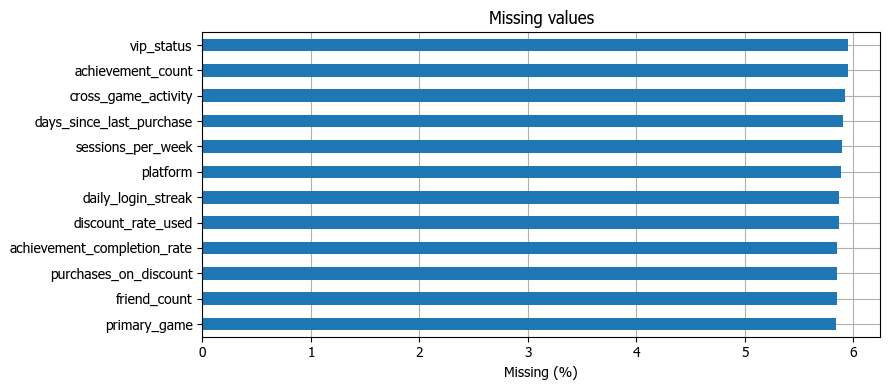

In [3]:
quality = quality_table(features)
display(quality.head(12))
print('Duplicate IDs:', int(frame.player_id.duplicated().sum()))
print('Duplicate feature rows:', int(features.duplicated().sum()))
if train is not None:
    print('Train/test ID overlap:', len(set(train.player_id) & set(test.player_id)))
    print('Missing target:', int(train[target].isna().sum()))
display(bounds_table(frame, 3))
display(outlier_table(features).head(8))
quality.missing_pct.head(12).sort_values().plot.barh(xlabel='Missing (%)', title='Missing values')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** Feature missing เฉลี่ย 5.82%; สูงสุด `vip_status` 5.95%; duplicate feature rows 0; พบค่าที่อยู่นอกช่วงตรวจทั้งหมด 0 จุด (นับระดับ cell); feature ที่มี IQR outlier สูงสุดคือ `avg_transaction_value` 15.00%

**Interpretation:** ค่าหลุด IQR เป็น outlier เชิงสถิติ ไม่ยืนยันว่าเป็นข้อมูลผิด ช่วงที่ตรวจมาจากความหมายใน data card และอาจสะท้อนนิยามหรือข้อมูลสังเคราะห์ที่ต่างออกไป

**ML Implications:** ใช้โมเดลรองรับ missing หรือ fit imputer เฉพาะ training fold; ยังไม่ clip ทั้งชุด

**Recommended Action:** ตรวจ feature ที่อยู่นอกช่วงกับนิยามต้นทาง และเก็บ missing indicator เมื่อใช้ imputer

In [4]:
missing_compare = pd.DataFrame({'train_pct': features.isna().mean() * 100,
                                'test_pct': test[features.columns].isna().mean() * 100})
missing_compare['gap_pp'] = missing_compare.test_pct - missing_compare.train_pct
display(missing_compare.sort_values('gap_pp', key=lambda x: x.abs(), ascending=False).head(10))
print('Duplicate test feature rows:', test[features.columns].duplicated().sum())
train_hash = pd.util.hash_pandas_object(features, index=False)
test_hash = pd.util.hash_pandas_object(test[features.columns], index=False)
print('Train/test identical feature row hashes:', len(set(train_hash) & set(test_hash)))

Duplicate test feature rows: 0
Train/test identical feature row hashes: 0


,train_pct,test_pct,gap_pp
seasonal_spending_pattern,5.6827,6.0103,0.3276
avg_transaction_value,5.7606,6.0605,0.2999
vip_status,5.9510,5.6935,-0.2574
segment,5.7067,5.9446,0.2379
avg_session_length,5.7721,5.5352,-0.2369
purchase_frequency,5.8077,5.6086,-0.1991
games_played,5.7981,5.6124,-0.1857
total_transactions,5.8337,5.6588,-0.1749
competitive_rank,5.7115,5.8828,0.1713
total_playtime_hours,5.8135,5.9755,0.1620


**Findings & Interpretation**

**Findings:** Missing ใน test เฉลี่ย 5.83%; ช่องว่าง train/test ที่มากสุดคือ `seasonal_spending_pattern` 0.33 percentage points

**Interpretation:** การเปรียบเทียบนี้ตรวจเฉพาะ missingness และ exact feature rows ยังไม่พิสูจน์ว่าไม่มี distribution shift

**ML Implications:** ใช้ preprocessing ที่รองรับ missing ในทั้งสอง split และหลีกเลี่ยง fit บน test สำหรับ supervised tasks

**Recommended Action:** หากคะแนนจริงต่างจาก holdout มาก ให้ตรวจ feature distribution และรูปแบบเก็บข้อมูลเพิ่มเติม

## 4. Statistical Analysis

,count,mean,std,min,25%,50%,75%,max
friend_count,"97,917.0000",110.4135,65.3898,0.0000,59.0000,106.0000,155.0000,410.0000
social_interactions,"97,956.0000",65.7487,37.8240,0.0000,36.0000,64.0000,92.0000,230.0000
guild_membership,"97,928.0000",0.6002,0.4899,0.0000,0.0000,1.0000,1.0000,1.0000
event_participation_rate,"97,971.0000",39.6481,18.5001,10.0018,25.4283,36.2447,53.0645,84.9998
daily_login_streak,"97,893.0000",56.5685,35.7169,0.0000,28.0000,53.0000,81.0000,256.0000
avg_session_length,"97,997.0000",110.2387,54.7514,20.0009,66.8518,105.9007,147.3101,364.4286
sessions_per_week,"97,869.0000",14.2628,7.5942,1.0003,8.3752,13.8664,19.4637,47.8019
total_playtime_hours,"97,954.0000",594.5627,292.8959,50.0117,374.3818,583.2547,794.3822,"1,980.9804"
days_since_last_login,"97,965.0000",7.3455,5.4541,0.0000,2.9884,6.2477,10.6077,40.9148
achievement_count,"97,812.0000",161.1983,81.0064,0.0000,102.0000,159.0000,216.0000,507.0000


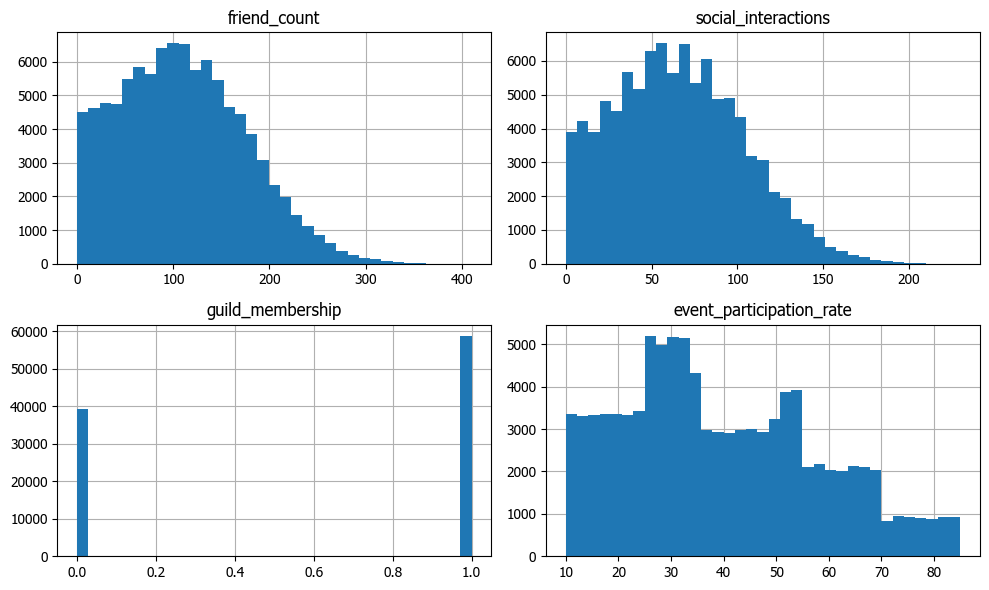

In [5]:
display(features.describe(include='all').T.head(12))
features[['friend_count', 'social_interactions', 'guild_membership', 'event_participation_rate']].hist(bins=35, figsize=(10, 6))
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** ข้อมูลตัวเลขมี 32 feature; `friend_count` median=106.000, p99=275.000; `social_interactions` median=64.000, p99=160.000; `guild_membership` median=1.000, p99=1.000; `event_participation_rate` median=36.245, p99=82.711

**Interpretation:** ช่วงและรูปทรงของ feature ต่างกัน จึงต้องอ่านแกนและหน่วยก่อนเปรียบเทียบ

**ML Implications:** Tree baseline ไม่ต้อง scale; หากเปลี่ยนเป็น linear/distance model ให้ scale ภายใน fold

**Recommended Action:** ตรวจ target และความสัมพันธ์กับ feature เพิ่มเพื่อเลือกการแปลงข้อมูล

,spending_30d
count,"104,000.0000"
mean,"10,497.0406"
std,"30,568.9614"
min,0.0000
50%,79.4350
90%,"37,718.8510"
95%,"75,969.7510"
99%,"150,032.2954"
max,"300,000.0000"


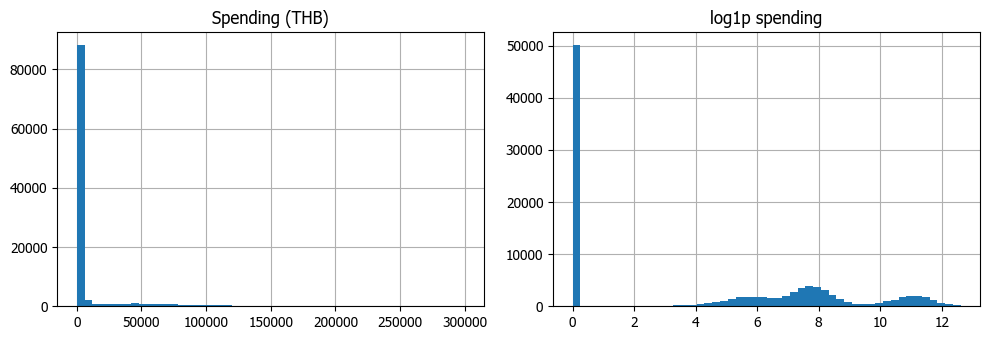

In [6]:
if target == 'spending_30d':
    display(frame[target].describe(percentiles=[.5, .9, .95, .99]).to_frame())
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    frame[target].hist(bins=50, ax=axes[0])
    axes[0].set_title('Spending (THB)')
    np.log1p(frame[target]).hist(bins=50, ax=axes[1])
    axes[1].set_title('log1p spending')
else:
    counts = frame[target].value_counts(dropna=False).sort_index()
    display(pd.DataFrame({'count': counts, 'pct': counts / len(frame) * 100}))
    counts.plot.bar(title='Target distribution', ylabel='Rows')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** Target เป็นศูนย์ 50,049 แถว (48.12%), mean 10,497.04, median 79.44, p99 150,032.30 THB

**Interpretation:** ยอดใช้จ่ายมีมวลที่ศูนย์และหางขวายาว ค่าเฉลี่ยห่างจาก median มาก

**ML Implications:** RMSE จะได้รับผลจากผู้ใช้จ่ายสูงมาก; log target อาจช่วย metric อื่นแต่ไม่ควรเลือกก่อนรู้กติกา

**Recommended Action:** ใช้เฉพาะ label ที่สังเกตได้และรายงาน metric หลายมุม

## 5. Feature Relationships

,abs_spearman
segment,0.6639
prev_month_spending,0.6520
historical_spending,0.6513
event_participation_rate,0.5876
avg_transaction_value,0.5378
vip_status,0.4208
is_premium_member,0.4027
owns_limited_edition,0.2730
total_transactions,0.2667
purchases_on_discount,0.2334


pearson_r
historical_spending      prev_month_spending       0.9954
event_participation_rate segment                   0.8797
total_transactions       purchases_on_discount     0.8740
vip_status               is_premium_member         0.8057
days_since_last_purchase purchase_frequency       -0.7331
games_played             cross_game_activity       0.7177
historical_spending      segment                   0.6568
prev_month_spending      segment                   0.6538
event_participation_rate historical_spending       0.5708
                         prev_month_spending       0.5690

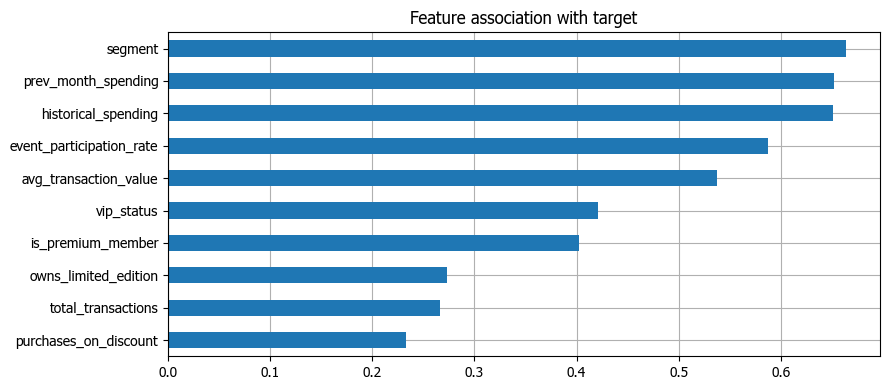

In [7]:
relevance = association(frame, target, regression=True)
display(relevance.head(12).rename('abs_spearman' if target == 'spending_30d' else 'eta_squared').to_frame())
display(strongest_pairs(features).rename('pearson_r').to_frame())
relevance.head(10).sort_values().plot.barh(title='Feature association with target')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** Feature ที่มี association สูงสุดคือ `segment` = 0.6639 (|Spearman|); คู่ feature ที่มี |Pearson r| สูงสุดคือ ('historical_spending', 'prev_month_spending') r=0.9954

**Interpretation:** ความสัมพันธ์คำนวณบนคู่ที่ไม่ missing ไม่ได้แสดงเหตุและผลหรือยืนยัน leakage

**ML Implications:** หลีกเลี่ยงใช้ correlation ของรหัส multiclass เป็นตัวชี้วัดหลัก; ยังไม่เลือก feature ด้วย validation ชุดสุดท้าย

**Recommended Action:** ตรวจ class-conditional patterns และเวลาที่ feature ถูกสร้างก่อน target

### Feature interactions

In [8]:
interaction_data = frame.assign(
    previous_spending_bin=pd.qcut(frame.prev_month_spending, 4, duplicates='drop'),
)
interaction = interaction_data.pivot_table(index='segment', columns='previous_spending_bin',
                                          values=target, aggfunc='median', observed=True)
display(interaction)
display(pd.crosstab(interaction_data.segment, interaction_data.previous_spending_bin))

previous_spending_bin,"(0.00692, 214.561]","(214.561, 551.735]","(551.735, 1436.413]","(1436.413, 63063.626]"
segment,,,,
0.0000,0.0000,0.0000,0.0000,NaN
1.0000,0.0000,0.0000,"1,004.6500","2,533.2050"
2.0000,104.5100,647.7450,"1,782.5500","3,813.1100"
3.0000,522.0950,"1,540.8650","4,421.7100","55,963.2800"


previous_spending_bin,"(0.00692, 214.561]","(214.561, 551.735]","(551.735, 1436.413]","(1436.413, 63063.626]"
segment,,,,
0.0000,20518,15505,991,0
1.0000,1680,5331,13455,2556
2.0000,943,2196,8413,7065
3.0000,50,72,234,13363


**Findings & Interpretation**

**Findings:** ตาราง interaction มี 4×4 ช่อง; ค่าที่สังเกตได้ต่ำสุด 0.0000, สูงสุด 55,963.2800

**Interpretation:** ตารางแสดง median ยอดใช้จ่าย THB ตาม segment และยอดใช้จ่ายเดือนก่อนร่วมกัน; ช่วง bin มาจาก quartile ของข้อมูลที่ใช้วิเคราะห์ และบางช่องอาจมีตัวอย่างน้อย

**ML Implications:** Tree model รองรับความสัมพันธ์ร่วมแบบนี้ได้; ยังไม่สร้างกฎตัดสินจาก EDA เพียงอย่างเดียว

**Recommended Action:** อ่านจำนวนตัวอย่างในแต่ละช่องก่อนตีความ และตรวจผลบน validation แยกจาก EDA

## 6. Task-Specific EDA

Rows at maximum target: 15


,count,mean,median,zero_fraction
segment,,,,
0.0000,39241,73.9579,0.0000,0.7244
1.0000,24483,944.3705,264.2500,0.4796
2.0000,19762,"2,283.8453","1,837.6400",0.3065
3.0000,14579,"65,357.7010","54,760.2800",0.0715


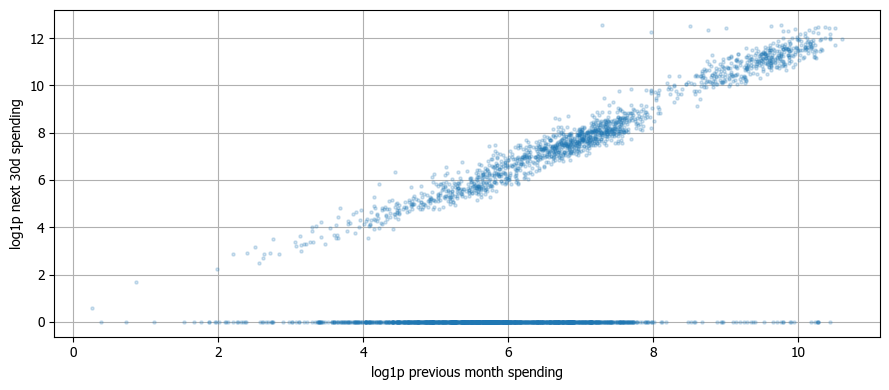

In [9]:
spending_by_segment = frame.groupby('segment')[target].agg(['count', 'mean', 'median'])
spending_by_segment['zero_fraction'] = frame.groupby('segment')[target].apply(lambda x: x.eq(0).mean())
display(spending_by_segment)
print('Rows at maximum target:', int(frame[target].eq(frame[target].max()).sum()))
sample = frame[['prev_month_spending', target]].dropna().sample(3000, random_state=42)
plt.scatter(np.log1p(sample.prev_month_spending), np.log1p(sample[target]), s=5, alpha=.2)
plt.xlabel('log1p previous month spending')
plt.ylabel('log1p next 30d spending')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** ค่าสูงสุด 300,000.00 THB พบ 15 แถว; prev_month_spending กับ target มี Spearman 0.6520

**Interpretation:** การซ้ำที่ค่าสูงสุดอาจเกิดจาก cap แต่เป็นสมมติฐาน ยังไม่มีหลักฐานยืนยัน historical spending ควรถูกบันทึกก่อนช่วง target

**ML Implications:** ยังไม่ตัดยอดใช้จ่ายสูง; segment เป็น input ที่ให้มาและไม่ควรเชื่อม Task 2 ด้วยสมมติฐานว่าเวลาเดียวกัน

**Recommended Action:** ตรวจ timestamp, target cap และ metric ทางการ; ลอง two-stage หรือ log target ในรอบถัดไป

## 7. EDA Findings & Insights

- Feature missing เฉลี่ย 5.82% และมีค่าที่อยู่นอกช่วงตรวจ 0 จุด
- Duplicate feature rows 0 แถว
- Train มี target ที่ทราบค่า 104,000 จาก 104,000 แถว
- ความสัมพันธ์เป็น observed association; leakage และสาเหตุของค่าผิดช่วงยังเป็นประเด็นที่ต้องตรวจ

## 8. Preprocessing Recommendations

- ไม่ใช้ player_id เป็น predictor และไม่เติม target ที่หาย
- Fit imputer/encoder เฉพาะ training fold; HistGradientBoosting รองรับ NaN ใน numerical features
- ยังไม่ลบ IQR outlier อัตโนมัติ เพราะอาจเป็นกลุ่มพฤติกรรมที่ต้องการทำนาย
- ตรวจ log1p ของ spending และเพิ่ม zero indicator เป็นตัวเลือกหลังยืนยัน metric
- Tree model ไม่จำเป็นต้อง scale; ถ้าใช้ linear/distance model ให้ scale ภายใน fold

## 9. Baseline Model Recommendations

เริ่ม HistGradientBoostingRegressor บน THB โดยตรง แบ่ง holdout 80/20 seed 42 เทียบ RMSE และ MAE กับ mean predictor; หากมี timestamp ให้เปลี่ยนเป็น temporal holdout

การฝึกโมเดลอยู่ใน `../02_baseline_submission.ipynb` ไม่มีการ fit ใน EDA notebook นี้

## 10. Final EDA Summary

ยืนยันจากข้อมูลในเครื่อง: 104,000 แถวที่ใช้วิเคราะห์, 32 feature, missing เฉลี่ย 5.82% และ known labels 104,000 แถว

ขั้นถัดไปคือรัน baseline แยกจาก EDA ตรวจ prediction และเก็บ local validation ก่อนปรับโมเดลให้ยืนยัน metric ทางการ วิธีจับคู่แถว submission และ provenance ของ feature ยังไม่สามารถพิสูจน์ temporal leakage หรือสาเหตุที่ข้อมูลบางค่าหลุดช่วงจากไฟล์ปัจจุบันได้